# Business Insights & Recommendations

## 1. Regular Customers
Regular customers show moderate income, spending, and purchasing frequency.

**Recommendation:**
- Provide loyalty rewards
- Offer personalized discounts
- Encourage repeat purchases

## 2. Potential Customers
Potential customers have relatively higher income and good average purchase value but moderate engagement.

**Recommendation:**
- Use targeted promotions
- Recommend premium products
- Introduce membership programs

## 3. High-Engagement Customers
High-engagement customers have the highest spending score and purchase frequency.

**Recommendation:**
- Provide loyalty benefits
- Offer exclusive products
- Use personalized recommendations
- Encourage referrals

## 4. Low-Engagement Customers
Low-engagement customers have high income but low spending and purchase frequency.

**Recommendation:**
- Send targeted offers
- Provide first/next-purchase discounts
- Use personalized marketing campaigns
- Identify reasons for low engagement

## Overall Business Insights

Customer segmentation helps the business understand differences in customer behavior.

The analysis can be used to:
- Improve customer targeting
- Create personalized marketing campaigns
- Increase customer retention
- Identify high-value opportunities
- Improve promotional strategies
- Increase customer lifetime value

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn plotly

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Create sample customer data

data = {
    "CustomerID": range(1, 31),
    
    "Age": [
        22, 25, 28, 35, 42, 45, 23, 31, 36, 50,
        27, 29, 41, 48, 24, 33, 38, 52, 26, 44,
        30, 34, 40, 55, 21, 39, 46, 32, 49, 37
    ],
    
    "Gender": [
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male"
    ],
    
    "AnnualIncome": [
        25000, 30000, 28000, 45000, 70000, 75000, 22000, 48000,
        55000, 90000, 32000, 35000, 65000, 85000, 27000, 50000,
        60000, 95000, 29000, 72000, 38000, 42000, 68000, 100000,
        20000, 58000, 80000, 46000, 88000, 62000
    ],
    
    "SpendingScore": [
        85, 78, 90, 55, 35, 30, 88, 60, 50, 25,
        80, 75, 40, 20, 92, 58, 45, 15, 87, 32,
        70, 65, 38, 10, 95, 48, 28, 62, 18, 42
    ],
    
    "PurchaseFrequency": [
        15, 12, 16, 8, 5, 4, 14, 9, 7, 3,
        13, 11, 6, 2, 17, 8, 6, 2, 15, 4,
        10, 9, 5, 1, 18, 7, 3, 10, 2, 6
    ],
    
    "AveragePurchaseValue": [
        45, 50, 42, 80, 150, 170, 40, 90, 110, 200,
        55, 60, 140, 220, 38, 95, 120, 250, 48, 160,
        70, 85, 130, 280, 35, 105, 190, 75, 230, 115
    ]
}

df = pd.DataFrame(data)

df.head()

,CustomerID,Age,Gender,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue
0,1,22,Female,25000,85,15,45
1,2,25,Male,30000,78,12,50
2,3,28,Female,28000,90,16,42
3,4,35,Male,45000,55,8,80
4,5,42,Female,70000,35,5,150


In [4]:
df.to_csv("data/customer_data.csv", index=False)

print("Customer dataset saved successfully!")

Customer dataset saved successfully!


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 30
Columns: 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   CustomerID            30 non-null     int64 
 1   Age                   30 non-null     int64 
 2   Gender                30 non-null     object
 3   AnnualIncome          30 non-null     int64 
 4   SpendingScore         30 non-null     int64 
 5   PurchaseFrequency     30 non-null     int64 
 6   AveragePurchaseValue  30 non-null     int64 
dtypes: int64(6), object(1)
memory usage: 1.8+ KB


In [6]:
df.isnull().sum()

CustomerID              0
Age                     0
Gender                  0
AnnualIncome            0
SpendingScore           0
PurchaseFrequency       0
AveragePurchaseValue    0
dtype: int64

In [7]:
df.describe()

,CustomerID,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,15.500000,36.066667,54666.666667,53.866667,8.266667,115.933333
std,8.803408,9.652348,23778.189562,25.857345,4.940566,69.504618
min,1.000000,21.000000,20000.000000,10.000000,1.000000,35.000000
25%,8.250000,28.250000,32750.000000,32.750000,4.250000,56.250000
50%,15.500000,35.500000,52500.000000,52.500000,7.500000,100.000000
75%,22.750000,43.500000,71500.000000,77.250000,11.750000,157.500000
max,30.000000,55.000000,100000.000000,95.000000,18.000000,280.000000


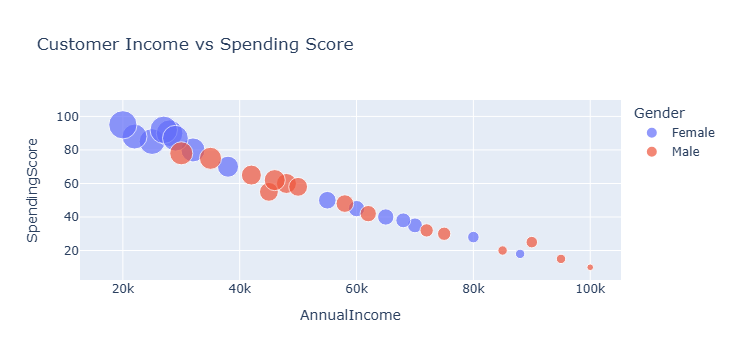

In [8]:
fig = px.scatter(
    df,
    x="AnnualIncome",
    y="SpendingScore",
    size="PurchaseFrequency",
    color="Gender",
    hover_data=["CustomerID", "Age"],
    title="Customer Income vs Spending Score"
)

fig.show()

In [9]:
features = [
    "Age",
    "AnnualIncome",
    "SpendingScore",
    "PurchaseFrequency",
    "AveragePurchaseValue"
]

X = df[features]

X.head()

,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue
0,22,25000,85,15,45
1,25,30000,78,12,50
2,28,28000,90,16,42
3,35,45000,55,8,80
4,42,70000,35,5,150


In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[-1.48224457, -1.2689707 ,  1.22462555,  1.38616526, -1.03800235],
       [-1.16612606, -1.05509924,  0.94928148,  0.76856688, -0.96483489],
       [-0.85000755, -1.14064782,  1.42129989,  1.59203139, -1.08190282],
       [-0.11239769, -0.41348484,  0.04457952, -0.05489763, -0.52583014],
       [ 0.62521216,  0.6558725 , -0.74211784, -0.67249602,  0.49851428]])

C:\Users\kusuma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

C:\Users\kusuma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

C:\Users\kusuma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

C:\Users\kusuma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks t

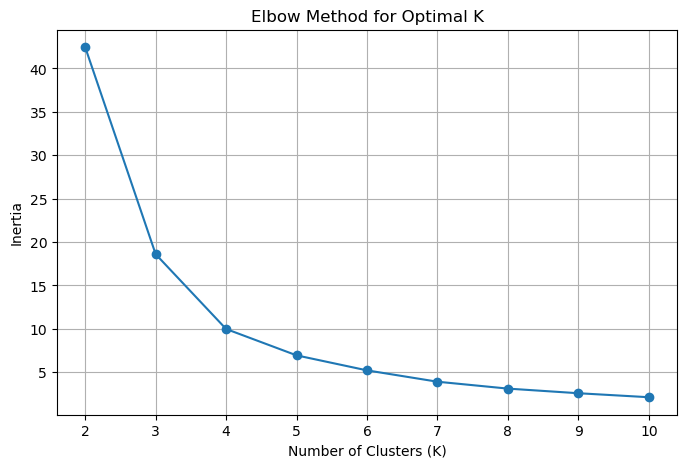

In [11]:
# Elbow Method

inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.grid(True)
plt.show()

In [12]:
# Apply K-Means clustering

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

df.head()

C:\Users\kusuma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.



,CustomerID,Age,Gender,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue,Cluster
0,1,22,Female,25000,85,15,45,2
1,2,25,Male,30000,78,12,50,2
2,3,28,Female,28000,90,16,42,2
3,4,35,Male,45000,55,8,80,0
4,5,42,Female,70000,35,5,150,1


In [13]:
cluster_counts = df["Cluster"].value_counts().sort_index()

cluster_counts

Cluster
0    7
1    9
2    8
3    6
Name: count, dtype: int64

In [14]:
cluster_profile = df.groupby("Cluster")[
    [
        "Age",
        "AnnualIncome",
        "SpendingScore",
        "PurchaseFrequency",
        "AveragePurchaseValue"
    ]
].mean().round(2)

cluster_profile

,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue
Cluster,,,,,
0,32.00,43428.57,63.57,9.29,79.29
1,40.22,65000.00,40.00,5.56,133.33
2,24.50,26625.00,86.88,15.00,44.12
3,50.00,89666.67,19.33,2.17,228.33


In [15]:
# Assign meaningful names to the clusters

segment_names = {
    0: "Regular Customers",
    1: "Potential Customers",
    2: "High-Engagement Customers",
    3: "Low-Engagement Customers"
}

df["Segment"] = df["Cluster"].map(segment_names)

df[["CustomerID", "Cluster", "Segment"]].head(10)

,CustomerID,Cluster,Segment
0,1,2,High-Engagement Customers
1,2,2,High-Engagement Customers
2,3,2,High-Engagement Customers
3,4,0,Regular Customers
4,5,1,Potential Customers
5,6,1,Potential Customers
6,7,2,High-Engagement Customers
7,8,0,Regular Customers
8,9,1,Potential Customers
9,10,3,Low-Engagement Customers


In [16]:
df[
    [
        "CustomerID",
        "Age",
        "AnnualIncome",
        "SpendingScore",
        "PurchaseFrequency",
        "AveragePurchaseValue",
        "Segment"
    ]
].sort_values("Segment")

,CustomerID,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue,Segment
0,1,22,25000,85,15,45,High-Engagement Customers
24,25,21,20000,95,18,35,High-Engagement Customers
18,19,26,29000,87,15,48,High-Engagement Customers
10,11,27,32000,80,13,55,High-Engagement Customers
6,7,23,22000,88,14,40,High-Engagement Customers
14,15,24,27000,92,17,38,High-Engagement Customers
1,2,25,30000,78,12,50,High-Engagement Customers
2,3,28,28000,90,16,42,High-Engagement Customers
17,18,52,95000,15,2,250,Low-Engagement Customers
26,27,46,80000,28,3,190,Low-Engagement Customers


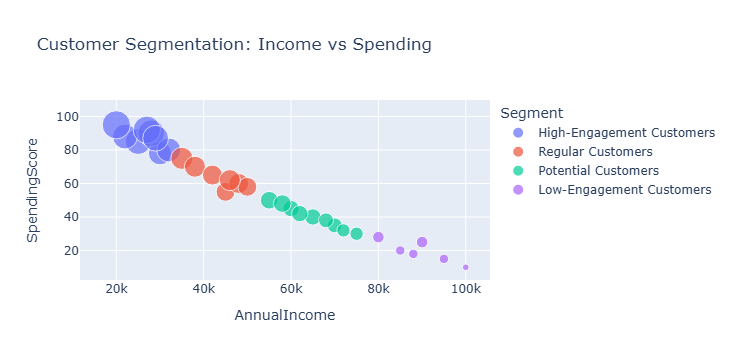

In [17]:
fig = px.scatter(
    df,
    x="AnnualIncome",
    y="SpendingScore",
    color="Segment",
    size="PurchaseFrequency",
    hover_data=[
        "CustomerID",
        "Age",
        "AveragePurchaseValue"
    ],
    title="Customer Segmentation: Income vs Spending"
)

fig.show()

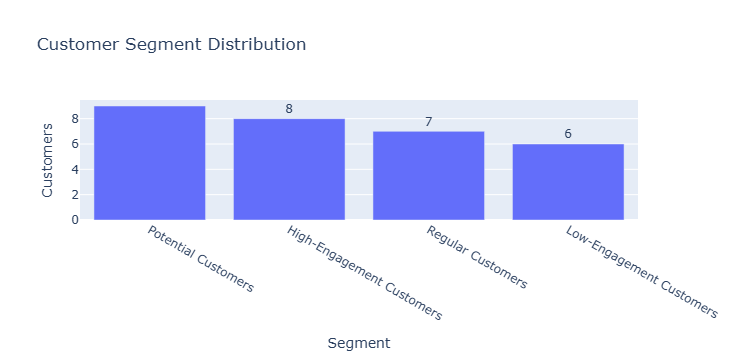

In [18]:
segment_counts = (
    df["Segment"]
    .value_counts()
    .reset_index()
)

segment_counts.columns = ["Segment", "Customers"]

fig = px.bar(
    segment_counts,
    x="Segment",
    y="Customers",
    text="Customers",
    title="Customer Segment Distribution"
)

fig.update_traces(
    textposition="outside"
)

fig.show()

In [19]:
final_profile = df.groupby("Segment")[
    [
        "Age",
        "AnnualIncome",
        "SpendingScore",
        "PurchaseFrequency",
        "AveragePurchaseValue"
    ]
].mean().round(2)

final_profile

,Age,AnnualIncome,SpendingScore,PurchaseFrequency,AveragePurchaseValue
Segment,,,,,
High-Engagement Customers,24.50,26625.00,86.88,15.00,44.12
Low-Engagement Customers,50.00,89666.67,19.33,2.17,228.33
Potential Customers,40.22,65000.00,40.00,5.56,133.33
Regular Customers,32.00,43428.57,63.57,9.29,79.29


In [20]:
df.to_csv("data/customer_segmentation_results.csv", index=False)

print("Customer segmentation results saved successfully!")

Customer segmentation results saved successfully!
